Detailed Problem Statement & Requirements
Implement a supervised classification model on the Iris or Wine dataset. Handle feature scaling (StandardScaler), train/test dataset splitting (80/20), train Logistic Regression and Decision Tree models, and benchmark classification accuracy, precision, recall, and F1-score.

Suggested Technical Approach
1. Load the benchmark dataset using Pandas. 2. Perform exploratory pairplots with Seaborn. 3. Normalize features using StandardScaler(). 4. Train LogisticRegression and DecisionTreeClassifier. 5. Plot the confusion matrix heatmap and plot the decision boundary visualization.

Recommended Tools:
Python
Scikit-Learn
Pandas
Seaborn / Matplotlib
Download Required Dataset / Starter File →
Expected Deliverable: Jupyter Notebook (.ipynb) with classification report metrics and plotted confusion matrix heatmap

In [2]:
from sklearn.datasets import load_iris
import pandas as pd

raw_data = load_iris()
df = pd.DataFrame(data=raw_data.data, columns=raw_data.feature_names)
df['target'] = raw_data.target
df['species'] = df['target'].map(dict(enumerate(raw_data.target_names)))

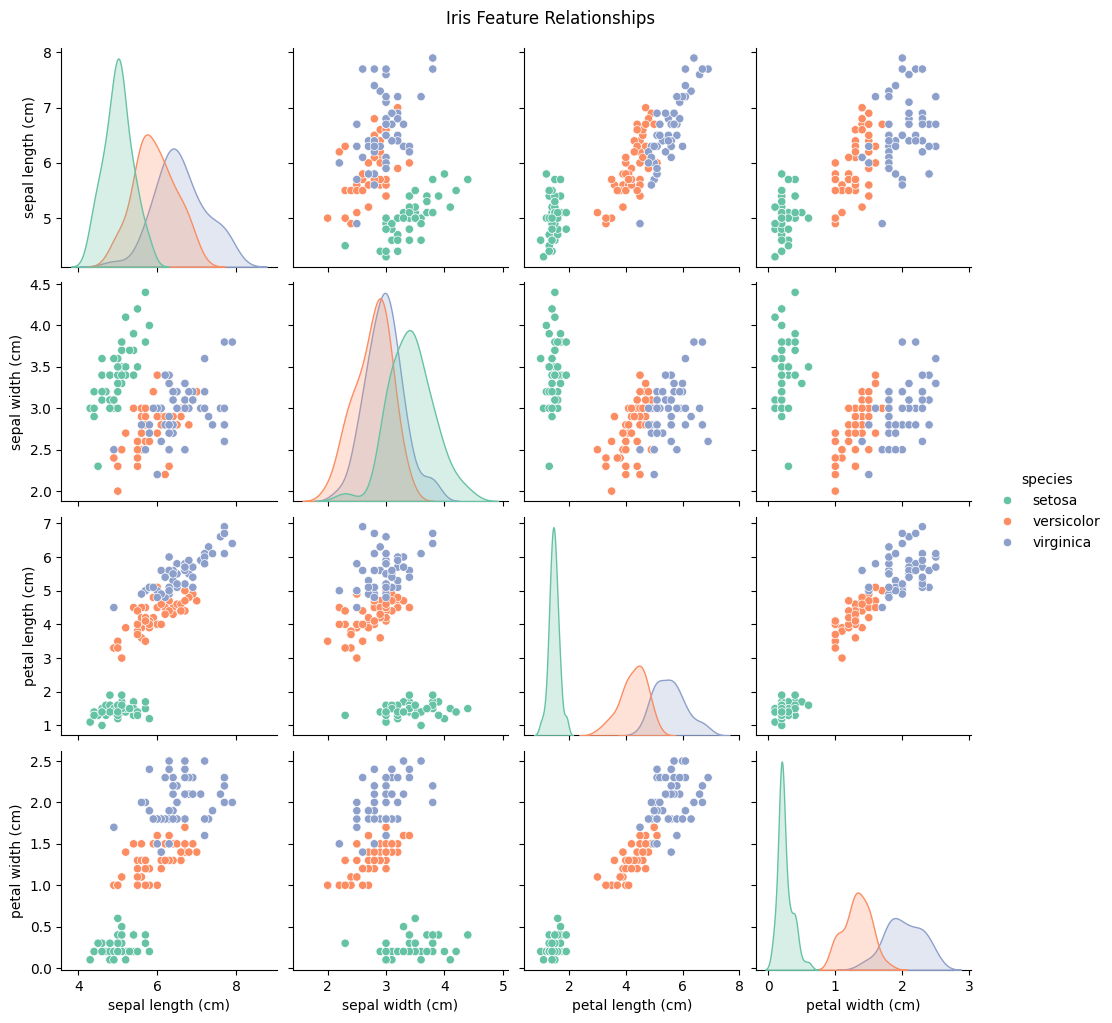

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df.drop(columns=['target']), hue='species', palette='Set2')
plt.suptitle("Iris Feature Relationships", y=1.02)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[raw_data.feature_names].values
y = df['target'].values

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=3)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1-Score": f1_score(y_test, y_pred, average='weighted')
    })

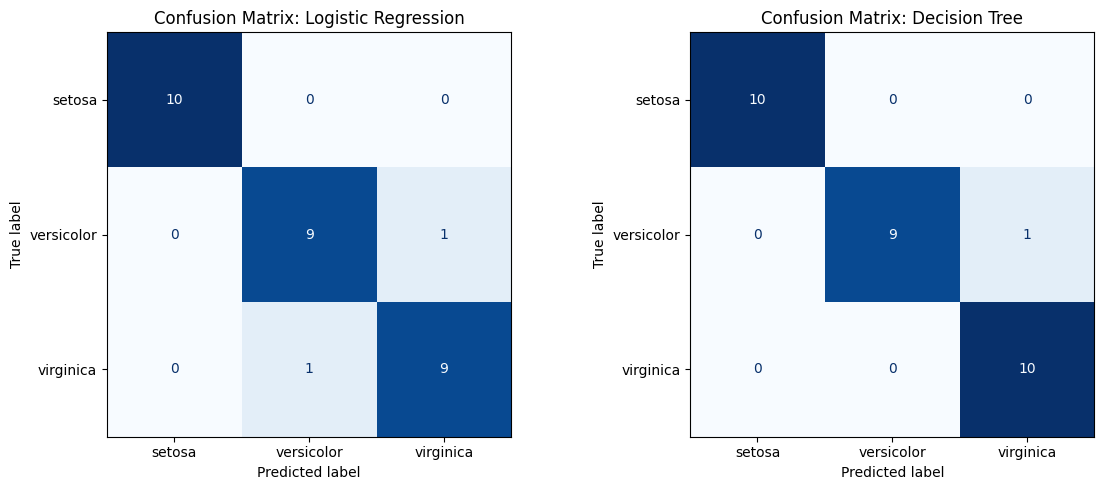

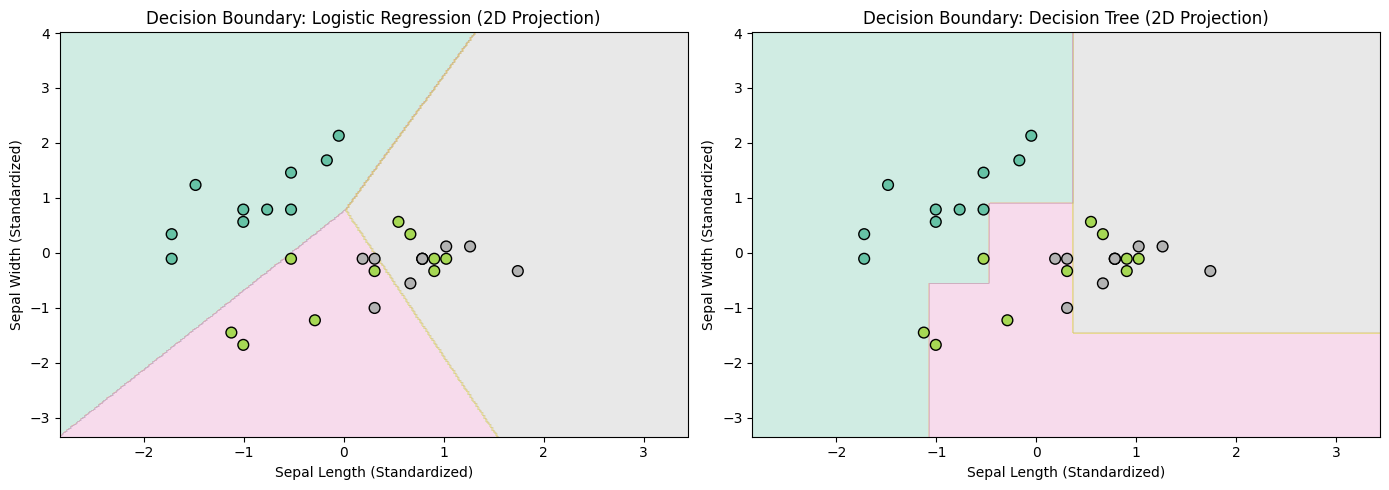

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------------------------
# Part A: Confusion Matrix Heatmaps
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, (name, model) in enumerate(models.items()):
    # Predict test targets
    y_pred = model.predict(X_test_scaled)

    # Generate confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot heatmap
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=raw_data.target_names)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].grid(False)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Part B: Decision Boundary Surface (2D Projection)
# ---------------------------------------------------------
# 1. Select the first two features (Sepal Length & Sepal Width) for 2D plotting
X_2d = X[:, :2]

# 2. Train/Test split and scale the 2D feature set
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.20, random_state=42, stratify=y
)

scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# 3. Create a meshgrid boundary range
x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# 4. Plot decision regions for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, model) in enumerate(models.items()):
    # Retrain on 2D scaled data for visualization
    model.fit(X_train_2d_scaled, y_train_2d)

    # Predict predictions across the entire grid surface
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Fill contour boundaries
    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set2)

    # Overlay actual test scatter points
    scatter = axes[idx].scatter(
        X_test_2d_scaled[:, 0], X_test_2d_scaled[:, 1],
        c=y_test_2d, cmap=plt.cm.Set2, edgecolors='k', s=60
    )
    axes[idx].set_title(f"Decision Boundary: {name} (2D Projection)")
    axes[idx].set_xlabel("Sepal Length (Standardized)")
    axes[idx].set_ylabel("Sepal Width (Standardized)")

plt.tight_layout()
plt.show()